## About the Data 

In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
data = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")

In [5]:
data.head()


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [6]:
data.shape

(235795, 56)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [8]:
data.shape

(235795, 56)

In [9]:
data.columns

Index(['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP',
       'TLD', 'URLSimilarityIndex', 'CharContinuationRate',
       'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain',
       'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
       'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL',
       'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
       'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
       'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength',
       'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore',
       'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect',
       'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
       'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
       'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
       'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
       'NoOfEmptyRef', 'NoOf

In [10]:
data.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [11]:
data.isna().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [12]:
data.duplicated().sum()

np.int64(0)

In [13]:
data["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

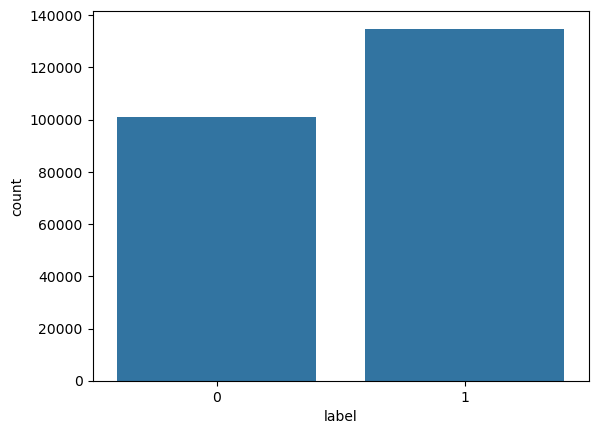

In [14]:
sns.countplot(x = 'label', data = data)
plt.show()

In [15]:
cat_fea = data.select_dtypes(include = "object").columns.tolist()
num_fea = data.select_dtypes(include = np.number).columns.tolist()
cat_fea

['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

In [16]:
num_fea

['URLLength',
 'DomainLength',
 'IsDomainIP',
 'URLSimilarityIndex',
 'CharContinuationRate',
 'TLDLegitimateProb',
 'URLCharProb',
 'TLDLength',
 'NoOfSubDomain',
 'HasObfuscation',
 'NoOfObfuscatedChar',
 'ObfuscationRatio',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'IsHTTPS',
 'LineOfCode',
 'LargestLineLength',
 'HasTitle',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'HasFavicon',
 'Robots',
 'IsResponsive',
 'NoOfURLRedirect',
 'NoOfSelfRedirect',
 'HasDescription',
 'NoOfPopup',
 'NoOfiFrame',
 'HasExternalFormSubmit',
 'HasSocialNet',
 'HasSubmitButton',
 'HasHiddenFields',
 'HasPasswordField',
 'Bank',
 'Pay',
 'Crypto',
 'HasCopyrightInfo',
 'NoOfImage',
 'NoOfCSS',
 'NoOfJS',
 'NoOfSelfRef',
 'NoOfEmptyRef',
 'NoOfExternalRef',
 'label']

In [17]:
for col in cat_fea:
    print(data[col].value_counts())
    print(col,data[col].nunique())

FILENAME
521848.txt      1
96605.txt       1
oph08639.txt    1
8024072.txt     1
8014599.txt     1
               ..
611368.txt      1
786974.txt      1
8008024.txt     1
702558.txt      1
384822.txt      1
Name: count, Length: 235795, dtype: int64
FILENAME 235795
URL
https://disclosepack.myportfolio.com/                                                         2
https://barlandas.com/reprisedefunction/unzupdm/                                              2
http://app-batasotak1244acces.kvoiffugw9-yk26ed5vg379.p.temp-site.link/termsofservice.html    2
https://fleek.ipfs.io/ipfs/qmzt2xz7uq7tdgiirmv7u7zaabtfhjn8jzouurbptgtgal/                    2
https://sucursalvirtualpersona.la-empresaempre.repl.co/                                       2
                                                                                             ..
https://www.clothdiaperkids.com                                                               1
https://www.toucansolution.com                             

In [18]:
cat_fea

['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

In [19]:
data.drop(['FILENAME', 'URL', 'Domain', 'TLD', 'Title'],axis = 1, inplace = True)

In [20]:
data.duplicated().sum()

np.int64(808)

In [21]:
data.drop_duplicates(inplace = True)

In [22]:
data.head()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,31,24,0,100.0,1.000000,0.522907,0.061933,3,1,0,...,0,0,1,34,20,28,119,0,124,1
1,23,16,0,100.0,0.666667,0.032650,0.050207,2,1,0,...,0,0,1,50,9,8,39,0,217,1
2,29,22,0,100.0,0.866667,0.028555,0.064129,2,2,0,...,0,0,1,10,2,7,42,2,5,1
3,26,19,0,100.0,1.000000,0.522907,0.057606,3,1,0,...,1,1,1,3,27,15,22,1,31,1
4,33,26,0,100.0,1.000000,0.079963,0.059441,3,1,0,...,1,0,1,244,15,34,72,1,85,1


In [23]:
data['URLSimilarityIndex'].value_counts()


URLSimilarityIndex
100.000000    135636
66.720000        742
66.695385        481
22.334010        369
60.845588        229
               ...  
28.437976          1
32.412856          1
8.519852           1
45.703020          1
47.074830          1
Name: count, Length: 36360, dtype: int64

In [24]:
data.drop('URLSimilarityIndex', axis = 1, inplace = True)

In [25]:
X = data.iloc[:,:-1]
y = data.iloc[:,-1]

## Outerlier Analysis

In [26]:
X.skew().sort_values(ascending =False)

NoOfCSS                       463.623478
NoOfObfuscatedChar            204.333391
NoOfJS                        140.358306
NoOfEqualsInURL               114.827329
NoOfEmptyRef                  106.651879
NoOfAmpersandInURL            106.534442
NoOfiFrame                     97.545200
NoOfDegitsInURL                94.798120
NoOfPopup                      84.807910
NoOfExternalRef                65.813172
NoOfSelfRef                    60.316294
NoOfLettersInURL               58.366715
URLLength                      53.280027
LineOfCode                     53.004208
LargestLineLength              48.100030
NoOfOtherSpecialCharsInURL     47.422904
ObfuscationRatio               40.049715
NoOfImage                      28.194175
HasObfuscation                 21.943507
IsDomainIP                     19.113492
NoOfQMarkInURL                  8.151050
Crypto                          6.285702
NoOfSelfRedirect                4.679533
HasExternalFormSubmit           4.440204
DegitRatioInURL 

In [27]:
X.kurtosis()

URLLength                       5901.124276
DomainLength                      10.796048
IsDomainIP                       363.328661
CharContinuationRate               0.060382
TLDLegitimateProb                 -1.973707
URLCharProb                        1.480015
TLDLength                         13.717506
NoOfSubDomain                      7.768188
HasObfuscation                   479.521575
NoOfObfuscatedChar             45746.080798
ObfuscationRatio                2118.039759
NoOfLettersInURL                8570.969351
LetterRatioInURL                   0.022662
NoOfDegitsInURL                14286.575981
DegitRatioInURL                   12.336520
NoOfEqualsInURL                19321.614694
NoOfQMarkInURL                    84.394522
NoOfAmpersandInURL             16379.365036
NoOfOtherSpecialCharsInURL      5650.535743
SpacialCharRatioInURL              0.981061
IsHTTPS                           -0.130894
LineOfCode                      5581.434131
LargestLineLength               

In [28]:

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR
    outliers = ((X[col]<lower)|(X[col]>upper)).sum()
    print(f"{col} :{outliers}")
    

URLLength :22388
DomainLength :13365
IsDomainIP :638
CharContinuationRate :679
TLDLegitimateProb :0
URLCharProb :8803
TLDLength :2134
NoOfSubDomain :57316
HasObfuscation :485
NoOfObfuscatedChar :485
ObfuscationRatio :485
NoOfLettersInURL :19563
LetterRatioInURL :1417
NoOfDegitsInURL :50667
DegitRatioInURL :50667
NoOfEqualsInURL :5394
NoOfQMarkInURL :6124
NoOfAmpersandInURL :887
NoOfOtherSpecialCharsInURL :12368
SpacialCharRatioInURL :3340
IsHTTPS :51189
LineOfCode :19194
LargestLineLength :17496
HasTitle :32594
DomainTitleMatchScore :0
URLTitleMatchScore :0
HasFavicon :0
Robots :0
IsResponsive :0
NoOfURLRedirect :31455
NoOfSelfRedirect :9454
HasDescription :0
NoOfPopup :13409
NoOfiFrame :34441
HasExternalFormSubmit :10366
HasSocialNet :0
HasSubmitButton :0
HasHiddenFields :0
HasPasswordField :24100
Bank :29873
Pay :55878
Crypto :5531
HasCopyrightInfo :0
NoOfImage :17298
NoOfCSS :17906
NoOfJS :11850
NoOfSelfRef :15576
NoOfEmptyRef :38879
NoOfExternalRef :22306


In [29]:
binary_cols = []
other_cols =[]
for col in X.columns:
    
    if X[col].nunique()==2:
        binary_cols.append(col)
    else:
        other_cols.append(col)
other_cols

['URLLength',
 'DomainLength',
 'CharContinuationRate',
 'TLDLegitimateProb',
 'URLCharProb',
 'TLDLength',
 'NoOfSubDomain',
 'NoOfObfuscatedChar',
 'ObfuscationRatio',
 'NoOfLettersInURL',
 'LetterRatioInURL',
 'NoOfDegitsInURL',
 'DegitRatioInURL',
 'NoOfEqualsInURL',
 'NoOfQMarkInURL',
 'NoOfAmpersandInURL',
 'NoOfOtherSpecialCharsInURL',
 'SpacialCharRatioInURL',
 'LineOfCode',
 'LargestLineLength',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'NoOfPopup',
 'NoOfiFrame',
 'NoOfImage',
 'NoOfCSS',
 'NoOfJS',
 'NoOfSelfRef',
 'NoOfEmptyRef',
 'NoOfExternalRef']

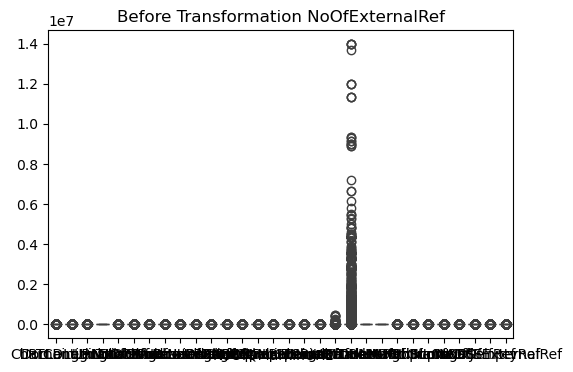

In [30]:

plt.figure(figsize=(6,4))
sns.boxplot(X[other_cols])
plt.title(f"Before Transformation {col}")
plt.show()

## Scaling

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state= 42, test_size = 0.3,stratify = y)
scaler = StandardScaler()
X_train_sca = scaler.fit_transform(X_train)
X_test_sca = scaler.transform(X_test)


In [32]:
X_train_sca

array([[ 0.34794758,  0.49906569, -0.05312914, ..., -0.37957489,
        -0.12525572, -0.3079119 ],
       [-0.3272708 , -0.81246827, -0.05312914, ..., -0.37365762,
        -0.12525572, -0.28883368],
       [10.37976344, -0.92176276, 18.82206095, ..., -0.38549217,
        -0.12525572, -0.31427131],
       ...,
       [ 0.22737287,  1.48271615, -0.05312914, ..., -0.38549217,
        -0.12525572, -0.31427131],
       [ 0.08268321,  1.15483266, -0.05312914, ..., -0.38549217,
        -0.12525572, -0.31427131],
       [-0.18258115, -0.04740679, -0.05312914, ..., -0.37957489,
        -0.12525572, -0.3079119 ]], shape=(164490, 49))

## Feature Selection

In [33]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
selector = SelectKBest(score_func =mutual_info_classif,
                       k = 25)
X_train_sel = selector.fit_transform(X_train_sca,y_train)
X_test_sel = selector.transform(X_test_sca)
                       

In [34]:
sel_fea = X_train.columns[selector.get_support()]

In [35]:
scores = selector.scores_[selector.get_support()]

In [36]:
fea_imp_score = pd.DataFrame({'Features ': sel_fea, 'scores':scores})

In [37]:
fea_imp_score

,Features,scores
0,URLLength,0.166172
1,CharContinuationRate,0.159855
2,TLDLegitimateProb,0.188459
3,LetterRatioInURL,0.381367
4,NoOfDegitsInURL,0.169966
5,DegitRatioInURL,0.173489
6,NoOfOtherSpecialCharsInURL,0.240324
7,SpacialCharRatioInURL,0.206448
8,IsHTTPS,0.240087
9,LineOfCode,0.599921


## Base Model

In [38]:
from sklearn.linear_model import LogisticRegression
m = LogisticRegression()
m.fit(X_train_sel, y_train)
y_pred_lr = m.predict(X_test_sel)


In [39]:
from sklearn.metrics import confusion_matrix,accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Matrix:",confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.9988510149368058
Matrix: [[29996    45]
 [   36 40420]]


## Cross Validation

In [40]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [41]:
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True, 
    random_state = 42
)
score = cross_val_score(
    m,
    X_train_sel,
    y_train,
    cv = cv,
    scoring = 'accuracy')
print(score.mean())
    

0.9988145175998542


## Pipeline

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [43]:
X_tarin, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.3, random_state = 42, stratify = y)
X_train.head()

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
185859,49,26,0,0.772727,0.522907,0.054162,3,1,0,0,...,0,0,0,0,0,0,1,1,0,1
215303,21,14,0,1.000000,0.032650,0.063895,2,1,0,0,...,0,0,0,1,32,2,2,2,0,4
51440,465,13,1,0.444444,0.000000,0.035865,3,2,0,0,...,0,0,0,0,1,0,0,0,0,0
51303,22,15,0,1.000000,0.000131,0.055424,2,1,0,0,...,0,0,0,0,0,0,0,0,0,0
158330,21,15,0,1.000000,0.000102,0.050409,2,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [44]:
preprocessor = Pipeline([
    ('scaler', RobustScaler()),
    ('selector',SelectKBest(score_func = mutual_info_classif, k = 30))])

In [45]:
preprocessor

,steps,"[('scaler', ...), ('selector', ...)]"
,transform_input,None
,memory,None
,verbose,False
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"
,copy,True
,unit_variance,False
,score_func,<function mut...001C704256FC0>
,k,30


## Pipeline Logistic Regression

In [46]:
model = LogisticRegression()

In [47]:
X_train_n = preprocessor.fit_transform(X_train,y_train)
X_test_n = preprocessor.transform(X_test)

In [48]:
model.fit(X_train_n,y_train)
y_pred_pip_lr = model.predict(X_test_n)

In [49]:
pip_lr_score = accuracy_score(y_test,y_pred_pip_lr)
print("Accuracy:",pip_lr_score)

Accuracy: 0.9995460799750344


In [50]:
confusion_matrix(y_test,y_pred_pip_lr)

array([[30028,    13],
       [   19, 40437]])

## Testing with synthetic test data

In [51]:
new_test = pd.read_csv("synthetic_phishing_5000.csv")
new_test.shape

(5000, 51)

In [52]:
X_n = new_test.iloc[:,:-1]
y_n = new_test.iloc[:,-1]

In [53]:
X_n.drop('URLSimilarityIndex',axis =1,inplace = True)

In [54]:
X_n.head()

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,50,41,0.0,0.868818,0.005977,0.043380,2,1,0.0,0,...,0.0,0.0,0.0,0.0,0,0,0,0,0,2
1,30,23,0.0,1.000000,0.522907,0.061552,3,1,0.0,0,...,1.0,1.0,0.0,1.0,90,3,17,88,0,9
2,21,14,0.0,1.000000,0.522907,0.062674,3,1,0.0,0,...,0.0,0.0,0.0,1.0,28,2,7,78,1,42
3,46,21,0.0,0.598994,0.522907,0.045180,3,1,0.0,0,...,0.0,0.0,0.0,0.0,0,2,8,3,0,1
4,36,27,0.0,0.590909,0.001766,0.044974,4,1,0.0,0,...,0.0,0.0,0.0,0.0,0,0,0,0,0,1


In [55]:
n_pred = preprocessor.transform(X_n)
y_pred_n = model.predict(n_pred)
accuracy_score(y_pred_n,y_n)

0.9994

## Pipeline DT

In [56]:
tree_model = Pipeline([
    ('preprocessor',preprocessor),
    ('model', DecisionTreeClassifier())])

In [57]:
tree_model

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('scaler', ...), ('selector', ...)]"
,transform_input,None
,memory,None
,verbose,False
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"


In [58]:
tree_model.fit(X_train, y_train)
y_pred_pip_dt = tree_model.predict(X_test)


In [59]:
print(accuracy_score(y_test,y_pred_pip_dt))
print(confusion_matrix(y_test,y_pred_pip_dt))

0.9982694299048186
[[29980    61]
 [   61 40395]]


## Hyperparameter Tuning

In [60]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC

X_train_sel = X_train.iloc[:60000,:]
y_train_sel = y_train.iloc[:60000]
X_test_sel = X_test.iloc[:60000,:]
y_test_sel = y_test.iloc[:60000]
svc = Pipeline([
    ('preprocessor',preprocessor),
    ('model', SVC())])
svc

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('scaler', ...), ('selector', ...)]"
,transform_input,None
,memory,None
,verbose,False
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"


In [61]:
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.1, 0.01],
    "model__degree": [2, 3], 
}
rand_svc = RandomizedSearchCV(estimator=svc,param_distributions = param_grid,cv= 5, scoring = 'accuracy',n_jobs =-1)
rand_svc.fit(X_train_sel,y_train_sel)
print("\nSVM:",rand_svc.best_params_)
print("Best Accuracy:", rand_svc.best_score_)


SVM: {'model__kernel': 'linear', 'model__gamma': 'scale', 'model__degree': 2, 'model__C': 10}
Best Accuracy: 0.9998166666666666


In [63]:
y_pred_tun_svm = rand_svc.predict(X_test_sel)
Hyp_svc_score =accuracy_score(y_test_sel,y_pred_tun_svm)
print("Accuracy:",Hyp_svc_score)

Accuracy: 0.99975


## Ensemble Learning

In [64]:
from sklearn.ensemble import AdaBoostClassifier
adaboost_model = AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=42)

In [65]:
ada_model = Pipeline([
    ('preprocessor',preprocessor),
    ('model', adaboost_model)])
ada_model.fit(X_train_sel,y_train_sel)
y_pred_boost = ada_model.predict(X_test_sel)


In [66]:
confusion_matrix(y_test_sel, y_pred_boost)

array([[25509,    28],
       [   23, 34440]])

In [67]:
ens_adaboost_score = accuracy_score(y_test_sel, y_pred_boost)
print("Accuracy:",accuracy_score(y_test_sel, y_pred_boost))

Accuracy: 0.99915


## Classification Metrics 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

model_predictions = {
    "Logistic Regression (Base)": y_pred_lr,

    "Logistic Regression (Pipeline)": y_pred_pip_lr,

    "Decision Tree (Pipeline)": y_pred_pip_dt,

    "SVM (Tuned)": y_pred_tun_svm,

    "AdaBoost": y_pred_boost,

    "Logistic Regression (External Test)": y_pred_n
}


In [68]:
import joblib

In [69]:
joblib.dump(rand_svc, "phishing_url_rand_svc.pkl")


['phishing_url_rand_svc.pkl']